# Module 2 – Illumination Correction (Elif Yeşilyurt, 240610008)

**Group project:** Image Enhancement in Licence Plate Recognition Systems (guideline topic 4).
**Module 2 (guideline):** *Correct uneven lighting caused by flash glare or shadows.*

| Item | Content |
|---|---|
| Input | 50 perspective-rectified plate crops (440×140 px) from CCPD-DB |
| Methods compared on the same crops | Original · **Global HE** · **CLAHE** · CLAHE + **Top/Black-Hat** · **Homomorphic** (all on LAB-L) |
| Expected output | Illumination-corrected crop of identical size and orientation, passed to Module 3 (binarization) |
| Primary metric | OCR Character Error Rate (Tesseract 5.5.4) vs. CCPD ground-truth plate text, paired-bootstrap 95 % CI |
| Auxiliary measures | luminance, local contrast, illumination non-uniformity, saturation, chroma shift (not OCR evidence) |

**Data source:** CCPD (Chinese City Parking Dataset), Xu et al., ECCV 2018, pp. 255–271, https://github.com/detectRecog/CCPD. **MIT License** (Copyright (c) 2017 CCPD). Subset: `ccpd_db`.

> The crops are a **temporary** rectification from CCPD corner annotations, *not* Module 1's final output (Gül Berra Aslan). See `INTEGRATION.md`.

This notebook reads the final run in `results_v2/` (produced by `src/run_pipeline.py`) and re-demonstrates every method live on one crop.

In [1]:
import os, sys, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
PROJECT = os.path.abspath('.')
sys.path.insert(0, os.path.join(PROJECT, 'src'))
import module2 as m2
R = os.path.join(PROJECT, 'results_v2')
plt.rcParams['font.family'] = ['Arial Unicode MS', 'Hiragino Sans GB', 'DejaVu Sans']
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 20)
METHODS = ['original', 'global_he', 'clahe', 'clahe_tophat', 'homomorphic']
print('OpenCV', cv2.__version__, '| numpy', np.__version__)

OpenCV 5.1.0 | numpy 2.0.2


## 1. Central configuration (exact values used in the reported run)

In [2]:
cfg = json.load(open(os.path.join(R, 'config_used.json')))
for k in ['crop', 'clahe', 'tophat', 'homomorphic', 'ocr']:
    print(k, '->', cfg[k])

crop -> {'width': 440, 'height': 140, 'interpolation': 'INTER_CUBIC', 'min_plate_width_px': 150, 'min_plate_height_px': 45}
clahe -> {'color_space': 'LAB', 'clip_limit': 2.0, 'tile_grid': [8, 2]}
tophat -> {'se_factor': 2.0, 'stroke_min': 3, 'stroke_max': 25, 'stroke_fallback_ratio': 0.07142857142857142, 'weight': 1.0}
homomorphic -> {'color_space': 'LAB', 'gamma_low': 0.5, 'gamma_high': 1.5, 'c': 1.0, 'd0': 10.0, 'pad': 'reflect', 'norm_percentiles': [0.5, 99.5]}
ocr -> {'engine': 'tesseract', 'lang': 'chi_sim', 'oem': 1, 'psm': 8, 'grayscale': True, 'whitelist': True, 'tessdata_dir': 'ocr/tessdata', 'calibration_seed': 7, 'calibration_n': 20}


## 2. Data: selection and ROI validation
* 30 candidates (seed 42; 10 dark / 10 mid / 10 bright by **CCPD filename brightness metadata**) and a 20-image seeded extension (seed 2026), giving the group plan of **50 difficult-lighting images**.
* CCPD-DB brightness metadata is bimodal (5–60 or 180–242), so **'mid' (22–39) is really 'dark-upper'**, the upper end of the dark mode.
* The filename is parsed exactly as in the official README: area – tilt – bbox – 4 vertices (RB, LB, LT, RT) – plate indices – brightness – blurriness.

In [3]:
man = pd.read_csv(os.path.join(R, 'manifest_roi.csv'), keep_default_na=False)
print(open(os.path.join(R, 'selection_rule.txt')).read())
display(man.groupby(['group', 'roi_status']).size().rename('n').reset_index())
display(man[man.roi_status != 'ok'][['id', 'group', 'plate_w_px', 'plate_h_px', 'roi_status', 'roi_reason']])

Original 30 candidates: elif_ccpd_db_selection/manifest.csv (seed 42; 10 dark/10 mid/10 bright by CCPD filename brightness metadata).
Extension (20): random.Random(2026).sample over sorted ccpd_db filenames not in the 30-candidate list, ROI valid and plate width >= 150px; dark: brightness <= 21 (pool 2231), bright: brightness >= 204 (pool 1587)
Group labels use CCPD filename brightness metadata (plate-region brightness as annotated by CCPD), not a local light measurement.



,group,roi_status,n
0,bright,ok,20
1,dark,ok,18
2,dark,review_required,2
3,mid,ok,10


,id,group,plate_w_px,plate_h_px,roi_status,roi_reason
1,S02,dark,130.6,46.1,review_required,small plate (131x46px) upsampled to 440x140
3,S04,dark,133.2,43.4,review_required,small plate (133x43px) upsampled to 440x140


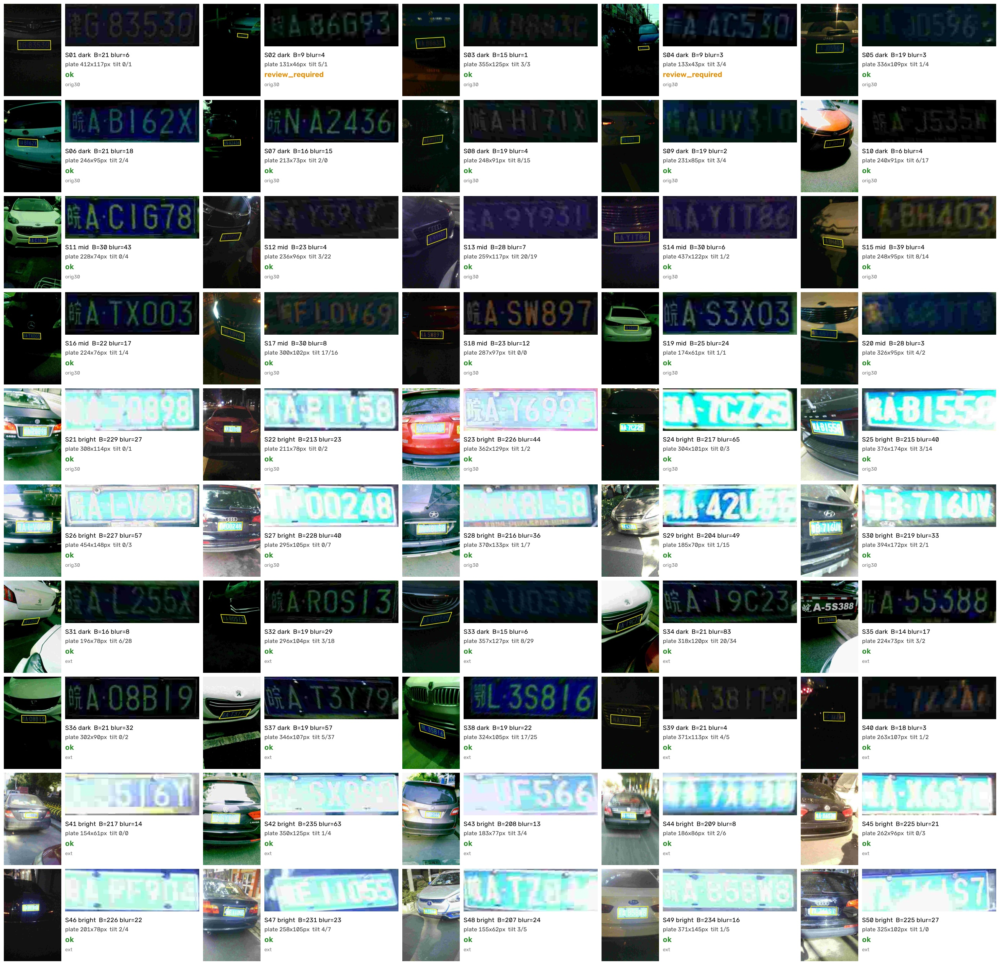

In [4]:
display(Image(os.path.join(R, 'figures/contact_sheet_roi.jpg'), width=1100))

## 3. Methods – live demonstration on one crop
* **Global HE**: a single histogram mapping for the whole crop (L channel). Global baseline.
* **CLAHE** [Pizer 1987; Zuiderveld 1994]: histogram equalisation per tile with a clip limit (2.0, 8×2 tiles) and bilinear blending. Adaptive and contrast-limited. Applied to L only, so hue is unchanged.
* **Top-Hat / Black-Hat** [Serra 1982], from our report: L' = L + TopHat(L) − BlackHat(L) after CLAHE, using an elliptical SE of 2× the stroke width estimated per crop.
* **Homomorphic** [Oppenheim et al. 1968; Gonzalez & Woods]: f = i·r ⇒ ln f = ln i + ln r. Steps: log1p(L) → FFT → H = (γH−γL)[1−exp(−c·D²/D0²)] + γL with γL = 0.5 (illumination attenuated), γH = 1.5 (edges boosted), D0 = 10 → inverse FFT → expm1 → 0.5–99.5 % stretch.

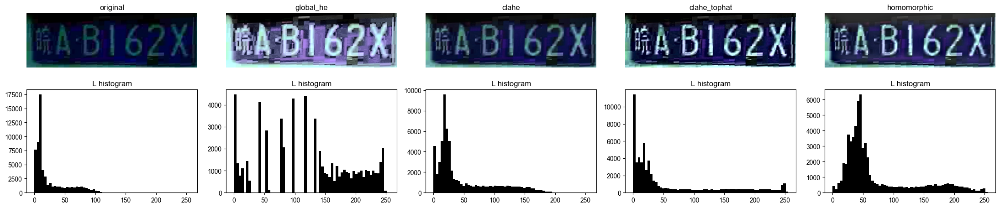

global_he     identical to saved result: True
clahe         identical to saved result: True
clahe_tophat  identical to saved result: True
homomorphic   identical to saved result: True


In [5]:
crop = cv2.imread(os.path.join(R, 'crops/original/S06.png'))
variants = {m: m2.correct_illumination(crop, m)[0] for m in METHODS}
fig, ax = plt.subplots(2, 5, figsize=(22, 5))
for j, (k, v) in enumerate(variants.items()):
    ax[0, j].imshow(cv2.cvtColor(v, cv2.COLOR_BGR2RGB)); ax[0, j].set_title(k); ax[0, j].axis('off')
    ax[1, j].hist(m2.luminance(v).ravel(), 64, (0, 255), color='k'); ax[1, j].set_title('L histogram')
plt.tight_layout(); plt.show()
for m in METHODS[1:]:
    saved = cv2.imread(os.path.join(R, f'crops/{m}/S06.png'))
    print(f'{m:13s} identical to saved result:', np.array_equal(saved, variants[m]))

## 4. Parameter choice
Parameters were fixed **before** OCR was run, by visual inspection of these sweeps on 3 crops (S06 dark, S17 dark-upper, S23 bright). Higher clip limits and higher γH visibly amplify JPEG 8×8 blocks in dark crops, so the moderate settings were kept.

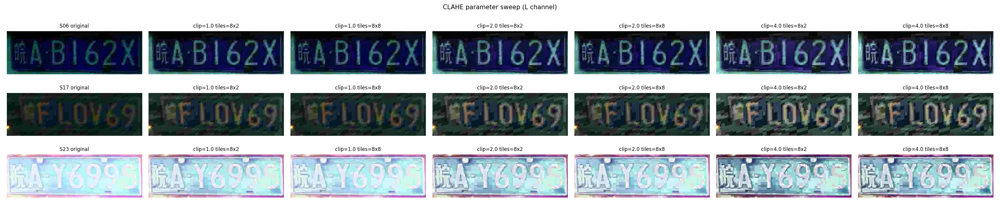

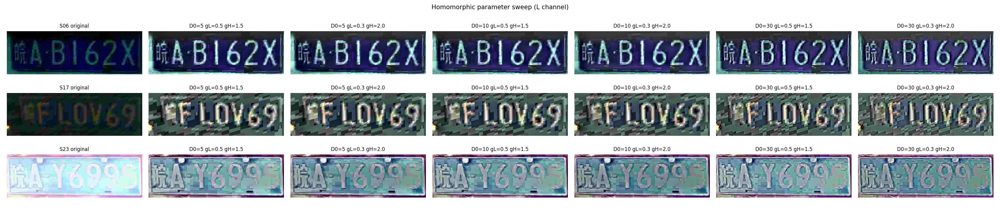

In [6]:
display(Image(os.path.join(R, 'figures/sweep_clahe.png'), width=1100))
display(Image(os.path.join(R, 'figures/sweep_homomorphic.png'), width=1100))

## 5. Evaluation – OCR Character Error Rate
* Engine: **Tesseract 5.5.4**, `chi_sim` (tessdata_fast), `--oem 1 --psm 8`, character whitelist, grayscale input. The settings are identical for all methods.
* OCR settings were selected on a **separate calibration set** of 20 CCPD-DB images (seed 7, disjoint from the test set), using only unprocessed crops (`ocr_calibration_grid.csv`).
* Ground truth: CCPD filename indices decoded with the official character tables. Normalisation: upper-case, keep only CJK/A–Z/0–9.
* **CER = Σ Levenshtein(OCR, GT) / Σ |GT|** per subset. `CER_alnum_6` ignores the province character. ΔCER 95 % CI: paired bootstrap over images, 5000 resamples.

In [7]:
print(open(os.path.join(R, 'ocr_settings.txt')).read())
summ = pd.read_csv(os.path.join(R, 'metrics_summary_ocr.csv'), keep_default_na=False)
display(summ[~summ.subset.str.startswith('exploratory')])

tesseract 5.5.4; pytesseract 0.3.13
lang=chi_sim; config: --tessdata-dir "ocr/tessdata" --oem 1 --psm 8 -c tessedit_char_whitelist=皖沪津渝冀晋蒙辽吉黑苏浙京闽赣鲁豫鄂湘粤桂琼川贵云藏陕甘青宁新警学ABCDEFGHJKLMNPQRSTUVWXYZ0123456789
Input: 440x140 crop of each method, converted BGR->GRAY (cv2), no other preprocessing.



,subset,method,n_images,CER_full,CER_alnum_6,exact_match,empty_outputs,imgs_better_than_orig,imgs_same_as_orig,imgs_worse_than_orig,dCER_vs_orig_95CI
0,all,original,50,0.6200,0.5633,0,3,,,,
1,all,global_he,50,0.7543,0.7300,0,3,6,19,25,"[+0.071, +0.197]"
2,all,clahe,50,0.6057,0.5467,0,2,9,33,8,"[-0.049, +0.017]"
3,all,clahe_tophat,50,0.6629,0.6100,0,3,10,23,17,"[-0.003, +0.091]"
4,all,homomorphic,50,0.6143,0.5667,0,2,14,25,11,"[-0.054, +0.046]"
5,group=dark,original,20,0.5571,0.4917,0,1,,,,
6,group=dark,global_he,20,0.7714,0.7583,0,2,1,5,14,"[+0.121, +0.314]"
7,group=dark,clahe,20,0.5429,0.4833,0,1,3,14,3,"[-0.064, +0.029]"
8,group=dark,clahe_tophat,20,0.5857,0.5167,0,0,3,11,6,"[-0.021, +0.079]"
9,group=dark,homomorphic,20,0.5000,0.4417,0,0,7,10,3,"[-0.136, +0.014]"


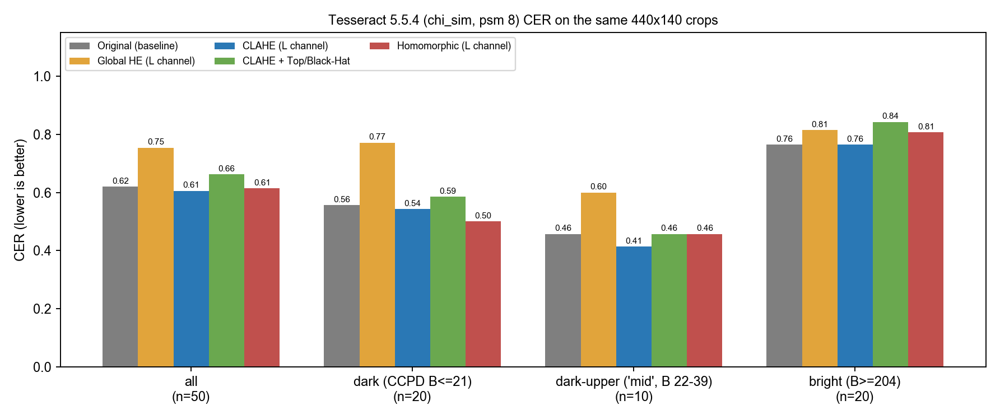

In [8]:
display(Image(os.path.join(R, 'figures/cer_by_group.png'), width=1000))

In [9]:
ocr = pd.read_csv(os.path.join(R, 'ocr_results_per_image.csv'), keep_default_na=False)
piv = ocr.pivot(index='id', columns='method', values='edit_dist')[METHODS]
piv['group'] = ocr.drop_duplicates('id').set_index('id').group
display(piv)

method,original,global_he,clahe,clahe_tophat,homomorphic,group
id,,,,,,
S01,2,5,2,2,2,dark
S02,4,5,3,4,3,dark
S03,7,7,7,6,7,dark
S04,5,5,3,4,4,dark
S05,7,7,7,7,6,dark
S06,1,6,1,2,1,dark
S07,1,5,1,2,2,dark
S08,7,7,7,7,5,dark
S09,6,5,4,5,6,dark


### 5.1 Global vs. adaptive (the report's planned comparison)
Global HE is the **only** method that is significantly worse than the original: its ΔCER CI excludes 0. The figure shows why. One global mapping stretches a dark-dominated histogram, so the background turns flat grey and JPEG blocks become as bright as strokes. CLAHE's tiles and clip limit prevent this.

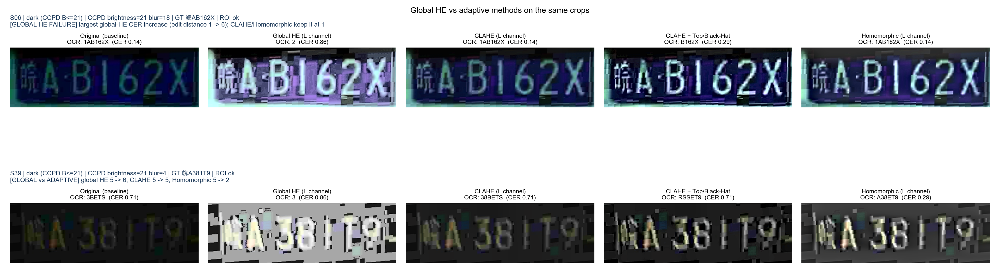

In [10]:
display(Image(os.path.join(R, 'figures/representative_global_vs_adaptive.png'), width=1100))

### 5.2 Uneven illumination and partial glare (**exploratory**)
Module 2's goal is *uneven* lighting, but the 50 images were selected by global brightness. The strata below are measured on the original crop: `illum_cv` > median means uneven, and 5–40 % saturated pixels means partial glare. They were defined **after** the first results were seen, and they overlap with the brightness groups: all uneven crops are dark or dark-upper, and all partial-glare crops are bright.

median illum_cv of original crops = 0.1491
uneven ids: S02,S03,S04,S05,S06,S07,S08,S09,S10,S11,S15,S16,S18,S19,S20,S31,S32,S33,S34,S35,S36,S37,S38,S39,S40
partial_glare ids: S22,S24,S25,S27,S29,S30,S41,S42,S44,S45,S46,S47,S48,S49,S50
Strata are EXPLORATORY: defined after the first run's results were seen.



,subset,method,n_images,CER_full,imgs_better_than_orig,imgs_worse_than_orig,dCER_vs_orig_95CI
30,exploratory:uneven(illum_cv>0.149),original,25,0.5257,,,
31,exploratory:uneven(illum_cv>0.149),global_he,25,0.7029,2,16,"[+0.091, +0.269]"
32,exploratory:uneven(illum_cv>0.149),clahe,25,0.4971,5,3,"[-0.074, +0.011]"
33,exploratory:uneven(illum_cv>0.149),clahe_tophat,25,0.5314,5,6,"[-0.040, +0.051]"
34,exploratory:uneven(illum_cv>0.149),homomorphic,25,0.4629,9,3,"[-0.126, -0.006]"
35,exploratory:uniform(illum_cv<=0.149),original,25,0.7143,,,
36,exploratory:uniform(illum_cv<=0.149),global_he,25,0.8057,4,9,"[+0.006, +0.183]"
37,exploratory:uniform(illum_cv<=0.149),clahe,25,0.7143,4,5,"[-0.051, +0.046]"
38,exploratory:uniform(illum_cv<=0.149),clahe_tophat,25,0.7943,5,11,"[+0.006, +0.160]"
39,exploratory:uniform(illum_cv<=0.149),homomorphic,25,0.7657,5,8,"[-0.017, +0.126]"


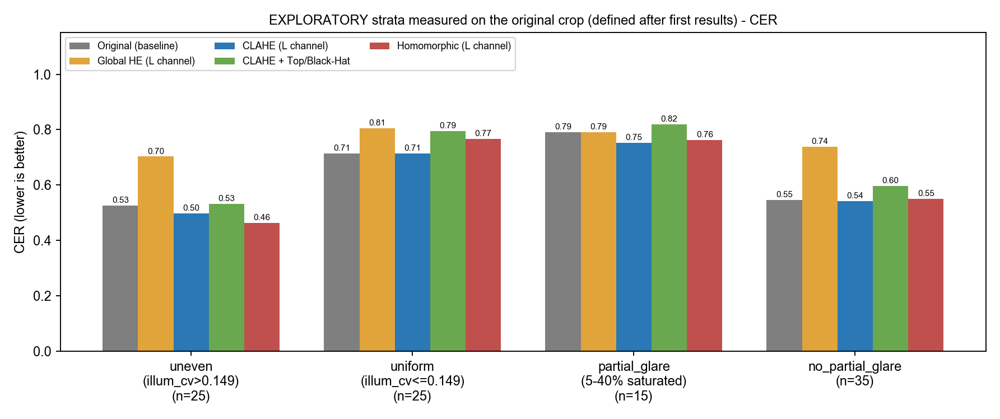

In [11]:
print(open(os.path.join(R, 'illumination_strata.txt')).read())
display(summ[summ.subset.str.startswith('exploratory')][['subset', 'method', 'n_images', 'CER_full', 'imgs_better_than_orig', 'imgs_worse_than_orig', 'dCER_vs_orig_95CI']])
display(Image(os.path.join(R, 'figures/cer_by_illumination_exploratory.png'), width=1000))

## 6. Auxiliary image measures (descriptive only – not evidence of OCR performance)

In [12]:
aux = pd.read_csv(os.path.join(R, 'metrics_aux_per_image.csv'))
cols = ['L_mean', 'local_contrast', 'illum_cv', 'sat_hi_frac', 'sat_lo_frac', 'chroma_shift']
display(aux.groupby(['group', 'method'])[cols].mean().round(3))
print('Top/Black-Hat: mean stroke estimate %.1f px, mean clipped fraction %.1f %%' %
      (aux.diag_stroke_px.mean(), 100 * aux.diag_tophat_clip_frac.mean()))
print('Homomorphic NaN/Inf pixels in total:', int(aux.diag_nan_or_inf.sum()))

L_mean  local_contrast  illum_cv  sat_hi_frac  sat_lo_frac  chroma_shift
group  method                                                                                 
bright clahe         196.508          21.556     0.149        0.044        0.000         0.181
       clahe_tophat  190.983          35.790     0.158        0.167        0.021         0.893
       global_he     132.449          38.436     0.297        0.038        0.008         1.454
       homomorphic   163.477          21.962     0.093        0.006        0.004         0.325
       original      220.168          13.192     0.101        0.105        0.000         0.000
dark   clahe          36.152          18.166     0.341        0.000        0.134         0.187
       clahe_tophat   45.631          35.412     0.347        0.009        0.276         0.554
       global_he     123.432          42.168     0.270        0.012        0.115         0.187
       homomorphic    67.126          30.493     0.146        0.005        0.012         0.172
       original       17.380           9.254     0.374        0.000        0.230         0.000
mid    clahe          52.657          21.407     0.246        0.000        0.017         0.182
       clahe_tophat   63.038          41.345     0.251        0.022        0.154         0.727
       global_he     135.914          43.597     0.193        0.013        0.021         0.385
       homomorphic    81.156          33.091     0.132        0.005        0.009         0.196
       original       28.237          10.660     0.259        0.000        0.059         0.000

Top/Black-Hat: mean stroke estimate 8.7 px, mean clipped fraction 18.1 %
Homomorphic NaN/Inf pixels in total: 0


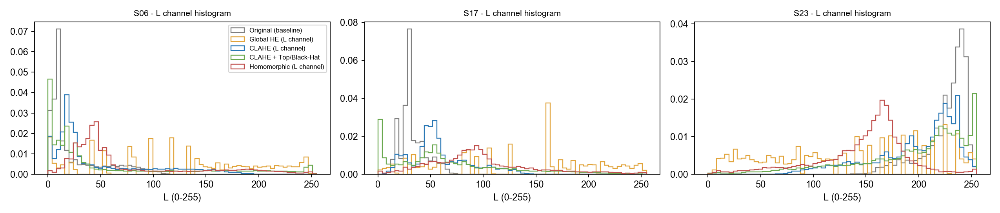

In [13]:
display(Image(os.path.join(R, 'figures/luminance_histograms.png'), width=1100))

## 7. Successful, unchanged and failed examples
Selection rule: the largest per-image change in OCR edit distance against the original, plus cases where all variants are identical. The observations in `review/visual_review.csv` describe only what is visible in the panels.

,id,category,method_focus,selection_reason,visual_observation
0,S39,success,homomorphic,largest CER decrease of any method in group da...,Very dark plate (CCPD brightness 21). Homomorp...
1,S15,success,all,all three methods reduce edit distance (4 -> 2...,Dim yellowish plate. All methods raise charact...
2,S45,success,clahe,largest CER decrease in group bright (edit dis...,Glare-washed plate. CLAHE restores local contr...
3,S18,unchanged,all,identical OCR for all four variants,Original is already well exposed and readable....
4,S49,unchanged,all,CER 1.00 for all four variants,Whole plate is overexposed: white characters o...
5,S14,failure,clahe_tophat+homomorphic,largest CER increase (edit distance 3 -> 7) in...,Dark plate with strong JPEG blocking. Top/Blac...
6,S26,failure,clahe_tophat+homomorphic,Top/Black-Hat edit distance 3 -> 7; Homomorphi...,Bright plate. Top/Black-Hat produces dark halo...
7,S10,failure,homomorphic,Homomorphic edit distance 5 -> 7 on the darkes...,Extremely dark plate. Homomorphic normalisatio...
8,S39,global_he_observation,global_he,added with the global-HE baseline (v2); global...,Global HE applies one mapping to the whole cro...


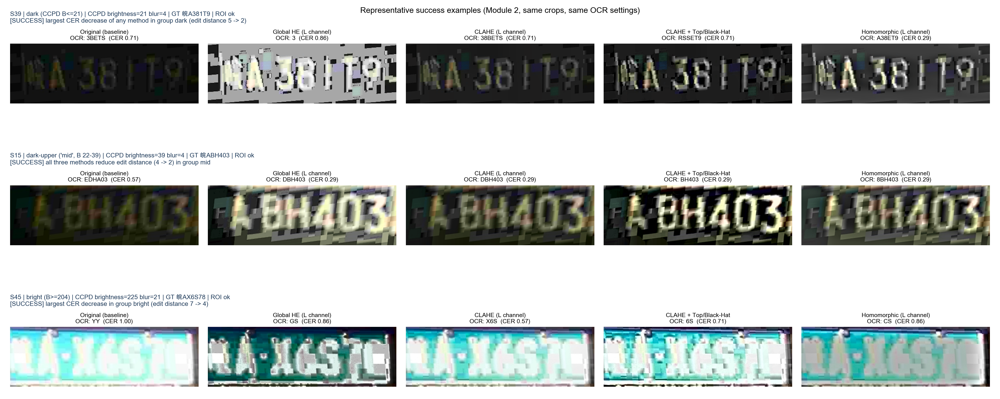

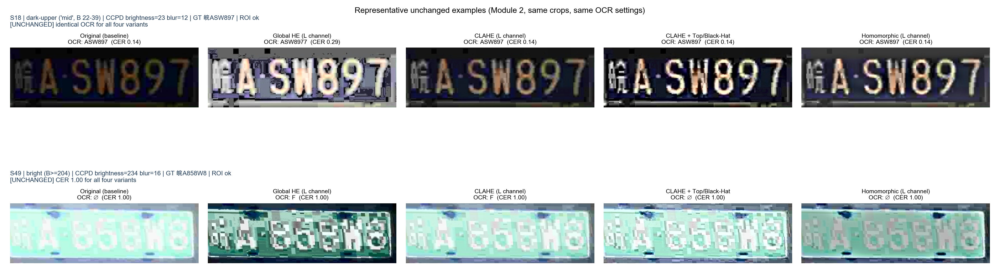

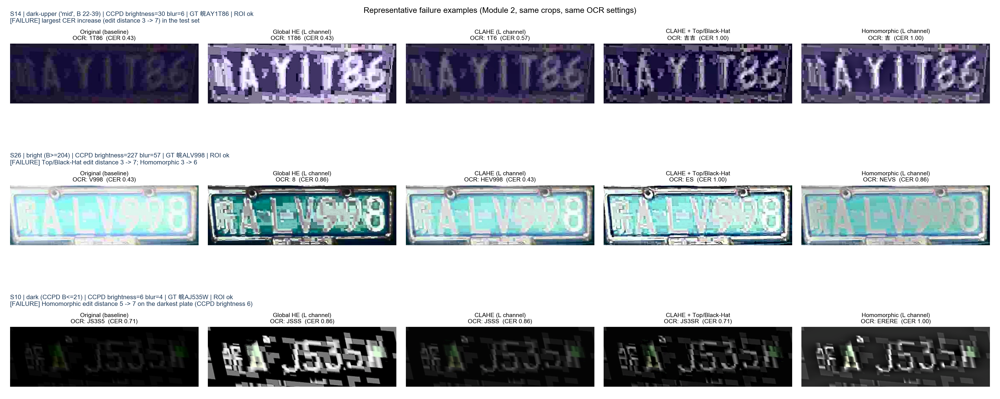

In [14]:
rv = pd.read_csv(os.path.join(PROJECT, 'review/visual_review.csv'))
display(rv)
for cat in ['success', 'unchanged', 'failure']:
    display(Image(os.path.join(R, f'figures/representative_{cat}.png'), width=1100))

## 8. Conclusion and limitations
1. **Adaptive beats global**: global HE significantly increases CER (0.754 vs 0.620, CI [+0.071, +0.197]). CLAHE avoids this (0.606).
2. **No method is clearly better than the original over all 50 images.** CLAHE is the safest default: best overall and never clearly worse in any subset.
3. **Homomorphic suits dark, unevenly lit plates**: 0.500 vs 0.557 on dark plates, and 0.463 vs 0.526 with a CI that excludes 0 in the exploratory uneven stratum. It hurts bright, uniform plates.
4. **Top/Black-Hat** (from our report) worsens OCR through halos and clipping, so it is not recommended before binarization.
5. **Failure causes**: saturated glare (information lost at capture), JPEG block amplification, halos, low resolution.

*Limitations:* temporary rectification (not Module 1); 50 images from one subset; brightness groups come from CCPD metadata; strata are post hoc and confounded with brightness; Tesseract is not a plate recogniser (0/50 exact matches, province character almost never read); image parameters were chosen on 3 test crops. No deep learning was used.

## 9. Re-running and integration
```bash
export CCPD_DB_DIR=/path/to/ccpd_db ELIF_SELECTION_DIR=/path/to/elif_ccpd_db_selection
.venv/bin/python src/run_pipeline.py --out results_rerun --stages roi,enhance,sweep,ocr,metrics,figures,calibrate
.venv/bin/python src/module2_cli.py --input-dir <module1_crops> --method clahe --out-dir <for_module3>
```
The runner never overwrites existing files. See `INTEGRATION.md` for the Module 1 → 2 → 3 contract.